# HW2_Q1_ADNI Classification

In [247]:
import torch
import numpy as np
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import cv2
import seaborn as sns
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import tensorflow as tf

import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from PIL import Image
import random

import torch.nn as nn
import gc

import torch.optim as optim
from sklearn.preprocessing import LabelEncoder


# Load ADNI dataset

In [248]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [249]:
image_path_list = []
label_list = []
label = []
image = []

path = '/content/drive/MyDrive/Data/Alzheimer_s_Disease_Neuroimaging_ADNI_Dataset'

for subfoder in tqdm(os.listdir(path)):
    subfoder_path = os.path.join(path,subfoder)
    for img_filename in os.listdir(subfoder_path):
        img_path = os.path.join(subfoder_path, img_filename)
        img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        image.append(img)
        label.append(subfoder)

img_arr = np.array(image)
label_arr = np.array(label)

print('dimension of img_arr', img_arr.shape)
print('dimension of label_arr', label_arr.shape)

for subfoder in tqdm(os.listdir(path)):
    subfoder_path = os.path.join(path,subfoder)
    for img_filename in os.listdir(subfoder_path):
        img_path = os.path.join(subfoder_path, img_filename)
        image_path_list.append(img_path)
        label_list.append(subfoder)


print(image_path_list[200])
print(label_list[200])


100%|██████████| 2/2 [00:14<00:00,  7.41s/it]


dimension of img_arr (1674, 256, 256, 3)
dimension of label_arr (1674,)


100%|██████████| 2/2 [00:00<00:00, 41.58it/s]

/content/drive/MyDrive/Data/Alzheimer_s_Disease_Neuroimaging_ADNI_Dataset/MCI/ADNI_141_S_1052_MR_AXIAL_T2_STAR__br_raw_20131227162238909_36_S209480_I403675.jpg
MCI


<class 'list'>


<ipython-input-250-d257889e9f48>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj


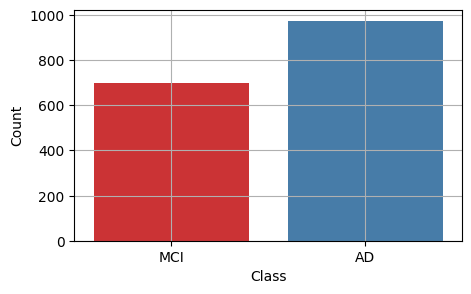

In [250]:
# numbers of each class
df = pd.DataFrame({'image':image , 'label':label})
print(type(image))

plt.figure(figsize= (5,3))
axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj
axis.set_xlabel('Class')
axis.set_ylabel('Count')
plt.grid(True)

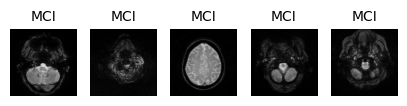

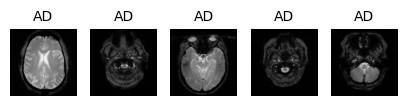

In [251]:
#show 5 pictures from each class
plt.figure(figsize= (5,3))
num_AD = img_arr[label_arr == 'AD'].shape[0]   # 965
num_MCI = img_arr[label_arr == 'MCI'].shape[0]   # 689

for i in range(5):
    n = np.random.randint(0,num_AD)
    plt.subplot(2,5,i+1)
    plt.imshow(img_arr[n])
    plt.title(label_arr[n], fontsize = 10)
    plt.axis('off')
plt.figure(figsize= (5,3))
for i in range(5):
    n = np.random.randint(num_AD + 1 ,num_MCI + num_AD)
    plt.subplot(2,5,i+1)
    plt.imshow(img_arr[n])
    plt.title(label_arr[n], fontsize = 10)
    plt.axis('off')

# Data Augmentation

In [252]:
img_1 = Image.open(image_path_list[1])
print(img_1.size)

(256, 256)


In [253]:
img_2 = cv2.imread(image_path_list[1], cv2.IMREAD_UNCHANGED)
print(img_2.shape)

(256, 256)


In [254]:
def Data_Augmentation(img_path_list , lbl_list):
  augmentation_factors = [
            "horizontal_flip",
            "shearing",
            "shifting",
            "rotation",
            "zooming"
        ]
  augmented_images = []
  augmented_labels = []

  for i in range(len(img_path_list)):
    image_path = img_path_list[i]
    img = Image.open(image_path)
    #print('type of img after Image.Open', type(img))
    #img = cv2.imread(image_path)
    #img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    label = lbl_list[i]

    # Normaize the img
    img = np.array(img)
    img = img/255

    transform_0 = transforms.ToPILImage()
    img = transform_0(img)

    # Resize all images to (64, 64)
    img = img.resize((64, 64))

    augmented_images.append(img)
    augmented_labels.append(label)


    # Offline data augmentation
    for _ in range(4):
        # Randomly choose an augmentation factor
        augmentation_factor = random.choice(augmentation_factors)

        if augmentation_factor == "horizontal_flip":
          img1 = transforms.RandomHorizontalFlip()(img)

        elif augmentation_factor == "shearing":
          img1 = transforms.RandomAffine(degrees=0, shear=20)(img)

        elif augmentation_factor == "shifting":
          trans_3 = transforms.RandomAffine(degrees=0, translate=(0.2, 0.2))(img)

        elif augmentation_factor == "rotation":
          img1 = transforms.RandomRotation(degrees=45)(img)

        elif augmentation_factor == "zooming":
          img1 = transforms.RandomResizedCrop(size=64, scale=(0.8, 1.2))(img)  #crop and resize

        #img2 = transforms.ToTensor()(img1)
        img2 = img1
        augmented_images.append(img1)
        augmented_labels.append(label)

  return augmented_images, augmented_labels

data_adni_images_list, data_adni_labels_list = Data_Augmentation(image_path_list , label_list)

#del image_path_list
#gc.collect()

print(len(data_adni_images_list))
print(len(data_adni_labels_list))


8370
8370


In [255]:
np.shape(data_adni_images_list[0])

(64, 64)

(8370, 64, 64)


30

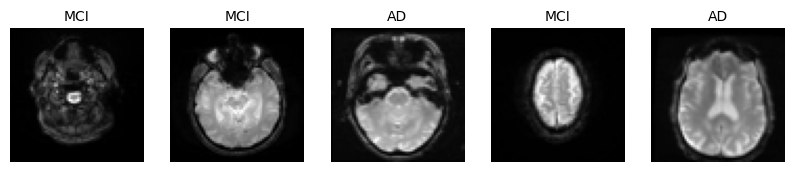

In [256]:
#show 5 pictures from each class
def plot_5_random(input_image_arr, input_label_arr, num ):
   num_AD = input_image_arr[input_label_arr == 'AD'].shape[0]
   num_MCI = input_image_arr[input_label_arr == 'MCI'].shape[0]
   plt.figure(figsize= (10,6))
   for i in range(5):
     n = np.random.randint(0,num_AD + num_MCI)
     plt.subplot(1,5,i+1)
     plt.imshow(np.squeeze(input_image_arr[n]), cmap = 'gray')
     plt.title(input_label_arr[n], fontsize = 10)
     plt.axis('off')

data_adni_images_arr2 = np.array(data_adni_images_list)
data_adni_labels_arr2 = np.array(data_adni_labels_list)
plot_5_random(data_adni_images_arr2,data_adni_labels_arr2, 5 )
print(data_adni_images_arr2.shape)
del data_adni_images_arr2, data_adni_labels_arr2
gc.collect()

<class 'list'>


<ipython-input-257-3c897ecc3ce0>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj


<function gc.collect(generation=2)>

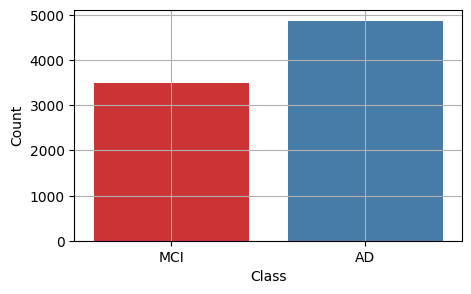

In [257]:
# numbers of each class after data augmentation
df = pd.DataFrame({'image':data_adni_images_list , 'label':data_adni_labels_list})
print(type(image))

plt.figure(figsize= (5,3))
axis = sns.countplot(x = df.label,palette = 'Set1')  #return the Axes obj
axis.set_xlabel('Class')
axis.set_ylabel('Count')
plt.grid(True)

del df
gc.collect

In [258]:
print(np.shape(data_adni_images_list))
data_adni_images_list = np.expand_dims(data_adni_images_list, axis=1)
print(np.shape(data_adni_images_list))

data_adni_images_arr = np.array(data_adni_images_list)
data_adni_labels_arr = np.array(data_adni_labels_list)


(8370, 64, 64)
(8370, 1, 64, 64)


In [259]:
from sklearn.model_selection import train_test_split

# Split into train and test sets
X_train_val, X_test, y_train_val, y_test = train_test_split(data_adni_images_arr,
                                                            data_adni_labels_arr,
                                                            test_size=0.05,
                                                            stratify=data_adni_labels_arr,
                                                            random_state=42)
# Split train to train and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_train_val
                                                  , y_train_val,
                                                  test_size=0.1,
                                                  stratify=y_train_val,
                                                  random_state=42)

# Print the sizes of the resulting sets
print("Train set size:", len(X_train))
print("Validation set size:", len(X_val))
print("Test set size:", len(X_test))
print(type(X_train))


Train set size: 7155
Validation set size: 796
Test set size: 419
<class 'numpy.ndarray'>


# Dataset and DataLoader with pytorch

In [260]:
class AdniDataset(Dataset):
    def __init__(self, data_array, label_array):
        self.data_array = data_array
        self.label_array = label_array

    def __len__(self):
        return len(self.data_array)

    def __getitem__(self, index):
        data = self.data_array[index]
        label = self.label_array[index]
        return data, label

In [261]:
# make train, test, val datasets
train_dataset = AdniDataset(X_train, y_train)
val_dataset = AdniDataset(X_val, y_val)
test_dataset = AdniDataset(X_test, y_test)


In [262]:
train_dataset[1]   # is a tupple

(array([[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]]], dtype=uint8),
 'MCI')

In [263]:
train_dataset[0]

(array([[[1, 0, 0, ..., 2, 1, 1],
         [1, 2, 2, ..., 0, 1, 1],
         [1, 2, 2, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 1, 1, 1],
         [0, 0, 0, ..., 1, 1, 1]]], dtype=uint8),
 'MCI')

In [264]:
# Create train, test, validation data_loaders
batch_size_model1 = 128   #########################################################################################################################################################
batch_size_model2 = 128
batch_size_model3 = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size_model1, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size_model2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size_model3, shuffle=False)


sample = next(iter(train_loader))
print(sample[0].shape)


torch.Size([128, 1, 64, 64])


In [265]:
sample = next(iter(train_loader))
print(sample[0].shape)
print(np.shape(sample[1]))   # sample[1] is a tuple of labels
print(type(sample[1]))
print(type(sample[1][0]))

torch.Size([128, 1, 64, 64])
(128,)
<class 'tuple'>
<class 'numpy.str_'>


# Part1
# CNN Mode1: Proposed Model

In [266]:
class CNN_Mode_Proposed(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
        nn.Conv2d(1,32, kernel_size=3 , padding=1),   # we want to extract 32 feature from this
        #nn.BatchNorm2d(32),
        nn.ReLU(),              # Input: (batch_size, 1, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.2),
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),
        #nn.BatchNorm2d(32),
        nn.ReLU(),             # Output: (batch_size, 32, 64, 64)
        nn.MaxPool2d(kernel_size=2, stride=2),
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),
        #nn.BatchNorm2d(32),
        nn.ReLU(),                # Output: (batch_size, 32, 32, 32)
        #nn.Dropout(0.2),
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),
        #nn.BatchNorm2d(32),
        nn.ReLU(),                # Output: (batch_size, 32, 32, 32)
        nn.MaxPool2d(kernel_size=2, stride=2)    # Output: (batch_size, 32, 16, 16)
    )


    self.flat = nn.Flatten()   # Input: (batch_size, 32, 16, 16), Output: (batch_size, 32*16*16)

    self.classifier = nn.Sequential(
        nn.Linear(32*16*16, 128),  # Input: (batch_size, 8192), Output: (batch_size, 128)
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),                 # Input: (batch_size, 128), Output: (batch_size, 64)
        #nn.Dropout(0.2),
        nn.Linear(64, 2),           # Input: (batch_size, 64), Output: (batch_size, 2)
        nn.Softmax(dim=1)
    )
    """
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           layer.weight.data.zero_()
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
           layer.weight.data.zero_()
           layer.bias.data.zero_()
           """



     # Xavier initialization for weights
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           torch.nn.init.xavier_uniform_(layer.weight,1)
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
            torch.nn.init.xavier_uniform_(layer.weight,1)
            layer.bias.data.zero_()

  def forward(self, x):
    x = self.feature_extractor(x)
    x = self.flat(x)
    x = self.classifier(x)
    return x

In [267]:
model1 = CNN_Mode_Proposed()
sample_2, label_2 = next(iter(val_loader))
sample_2

print(type(sample_2))
print(sample_2.shape)

model1(sample_2.float()).shape

<class 'torch.Tensor'>
torch.Size([128, 1, 64, 64])


torch.Size([128, 2])

# Training model1: Proposed

In [268]:
torch.cuda.is_available()

True

In [269]:
def accuracy_fn(pred,true):
    pred = torch.argmax(pred, dim=1)
    acc = (true == pred).float().mean().item()
    return acc

In [270]:
#batch_size_model1 = 128
epochs = 30
learning_rate = 0.0001


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN_Mode_Proposed().to(device)

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimzier
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

top1_acc_train = []
top1_acc_val = []
loss_avg_train = []
loss_avg_val = []

for epoch in range(1, epochs + 1):
    sum_train_acc_epoch = 0
    sum_val_acc_epoch = 0
    sum_train_loss_epoch = 0
    sum_val_loss_epoch = 0

    model.train()
    mode = "train"

    for batch_idx, (images, labels) in enumerate(train_loader,1):
        images = images.to(device)

        unique_classes = list(set(labels))
        labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
        labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)
        optimizer.zero_grad()    # prevent accumulate the gradients

        labels = labels_tensor.to(device)
        labels_pred = model(images.float())
        loss = loss_fn(labels_pred, labels.squeeze())


        #optimizer.zero_grad()    # prevent accumulate the gradients
        loss.backward()
        optimizer.step()   # update the weights

        #acc1 = accuracy(labels_pred, labels.squeeze())
        acc1 = accuracy_fn(labels_pred, labels.squeeze())
        sum_train_acc_epoch += acc1
        sum_train_loss_epoch += loss.detach().item()    # make independent from graph
        if batch_idx % int(round(len(train_loader)/6)) ==0:   # set how many times show the acc in each epoch
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for train ------>  {(sum_train_acc_epoch/batch_idx)*100}")
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for train ---------->  {sum_train_loss_epoch/batch_idx}")
    top1_acc_train.append(sum_train_acc_epoch / batch_idx)
    loss_avg_train.append(sum_train_loss_epoch / batch_idx)


    model.eval()
    mode = "val"

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader,1):
            images = images.to(device)

            unique_classes = list(set(labels))
            labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)

            labels = labels_tensor.to(device)
            labels_pred = model(images.float())
            loss = loss_fn(labels_pred, labels.squeeze())
            acc1 = accuracy_fn(labels_pred, labels.squeeze())
            sum_val_acc_epoch += acc1
            sum_val_loss_epoch += loss.detach().item()
            if batch_idx % int(round(len(val_loader)/6)) ==0:
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for valid ------>  {(sum_val_acc_epoch/batch_idx)*100}")
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for valid ---------->  {sum_val_loss_epoch/batch_idx}")

        top1_acc_val.append(sum_val_acc_epoch / batch_idx)
        loss_avg_val.append(sum_val_loss_epoch / batch_idx)


At epoch 1, till batch_index 9: average accuracy for train ------>  58.59375
At epoch 1, till batch_index 9: average loss for train ---------->  0.7069011198149787
At epoch 1, till batch_index 18: average accuracy for train ------>  59.592013888888886
At epoch 1, till batch_index 18: average loss for train ---------->  0.6950527992513444
At epoch 1, till batch_index 27: average accuracy for train ------>  61.63194444444444
At epoch 1, till batch_index 27: average loss for train ---------->  0.6706930994987488
At epoch 1, till batch_index 36: average accuracy for train ------>  63.28125
At epoch 1, till batch_index 36: average loss for train ---------->  0.6560090796815025
At epoch 1, till batch_index 45: average accuracy for train ------>  64.61805555555556
At epoch 1, till batch_index 45: average loss for train ---------->  0.6423509067959255
At epoch 1, till batch_index 54: average accuracy for train ------>  65.79861111111111
At epoch 1, till batch_index 54: average loss for train -

In [271]:
top1_acc_val

[0.7372449040412903,
 0.7386798518044608,
 0.786033170563834,
 0.8507653134209769,
 0.8718112281390599,
 0.8753188848495483,
 0.8926977089473179,
 0.903220670563834,
 0.9016262803758893,
 0.9038584232330322,
 0.9083227089473179,
 0.8947704178946358,
 0.9228316375187465,
 0.9183673518044608,
 0.918845670563834,
 0.9339923518044608,
 0.918845670563834,
 0.9288903134209769,
 0.9154974562781197,
 0.9339923518044608,
 0.9272959232330322,
 0.9284119946616036,
 0.9339923518044608,
 0.934630104473659,
 0.9368622473308018,
 0.9284119946616036,
 0.9406887803758893,
 0.9413265330450875,
 0.942442604473659,
 0.9413265330450875]

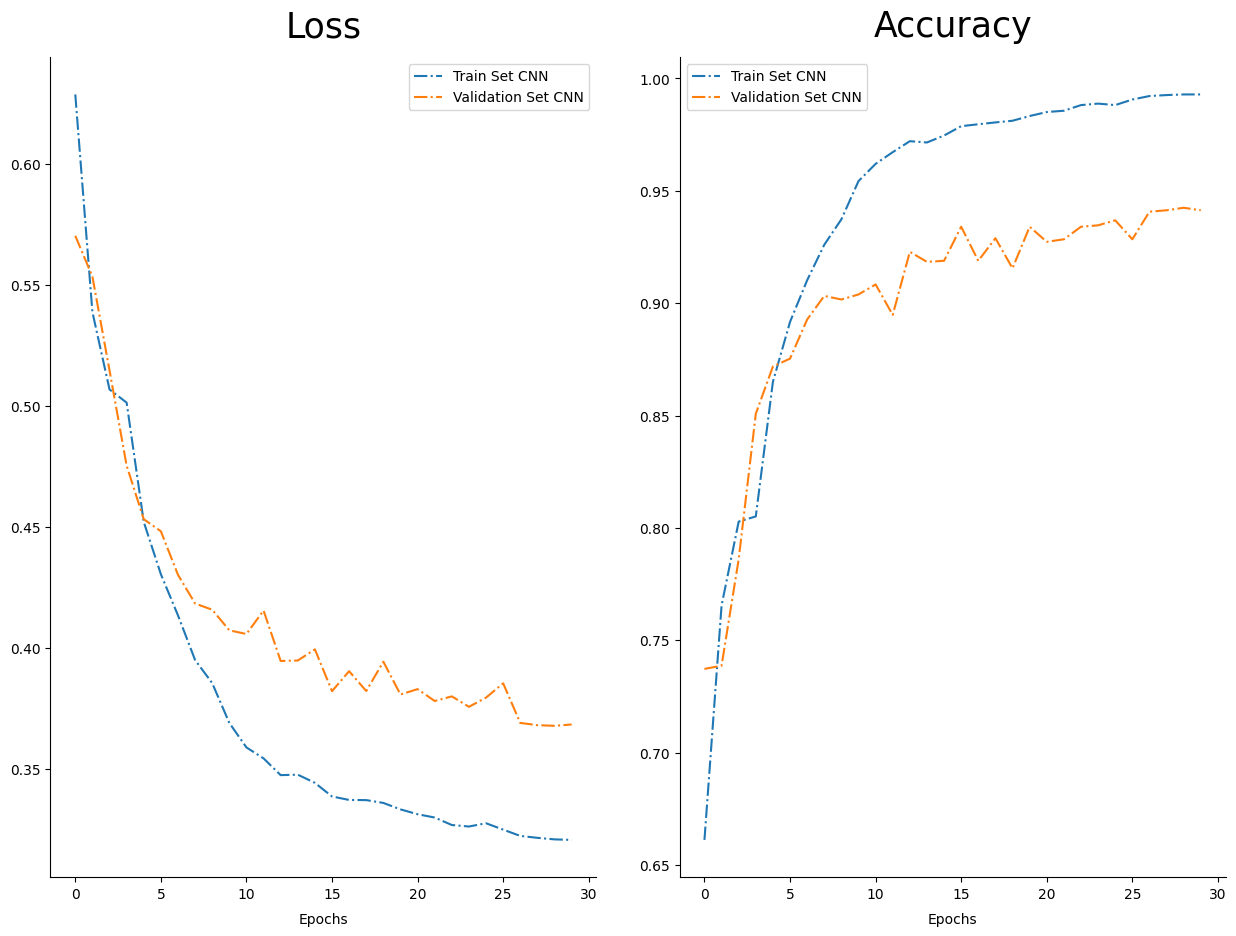

In [272]:
def accloss_plots(train_loss1, test_loss1, train_acc1, test_acc1):
    num_epochs = len(train_loss1)
    plt.figure(figsize=(13, 10))

    # Plot training loss for all sets
    plt.subplot(121)
    plt.plot(train_loss1, '-.', label='Train Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Loss', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot testing loss for all sets
    #plt.subplot(223)
    plt.plot(test_loss1, '-.', label='Validation Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Loss', fontsize=25, pad=15)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot training accuracy for all sets
    plt.subplot(122)
    plt.plot(train_acc1, '-.', label='Train Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Accuracy', fontsize=25, pad=15)
    plt.tight_layout(pad=3)
    plt.grid()
    plt.legend()
    sns.despine()

    # Plot testing accuracy for all sets
    #plt.subplot(224)
    plt.plot(test_acc1, '-.', label='Validation Set CNN')
    plt.xlabel('Epochs', fontsize=10, labelpad=8)
    plt.title('Accuracy', fontsize=25, pad=15)
    plt.tight_layout(pad=3)
    plt.grid()
    plt.legend()
    sns.despine()

    plt.show()

accloss_plots(loss_avg_train, loss_avg_val, top1_acc_train, top1_acc_val)


In [273]:
def eval_test(test_loader, model):

    scores = []
    labels_list = []
    total_loss = 0
    total_samples = 0
    model.to(device)
    model.eval()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels_encoded = LabelEncoder().fit_transform(labels)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)
            labels = labels_tensor.to(device)
            labels_pred = model(images.float())

            loss = loss_fn(labels_pred.squeeze(), labels.squeeze())
            scores.extend(labels_pred.cpu().numpy()[:, 1])  # Use only the positive class scores
            labels_list.extend(labels.squeeze().cpu().numpy())
            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

    accuracy = accuracy_fn(labels_pred, labels.squeeze())
    loss = total_loss / total_samples

    return accuracy, loss, scores, labels_list

In [274]:
# Test Proposed Model                 #&&&&&&&&&&&&&&&&&&&&&
test_acc, test_loss, scores, labels_list = eval_test(test_loader, model)
print(f"Test accuracy for proposed_model: {test_acc * 100}%")
print(f"Test loss for proposed_model: {test_loss}")
len(labels_list)

Test accuracy for proposed_model: 100.0%
Test loss for proposed_model: 0.362137613618004


419

# Plot the ROC for Proposed Model

In [275]:
from sklearn.metrics import roc_curve, confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score, auc, classification_report

def plot_roc_curve(labels, scores):
    fpr, tpr, _ = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

In [276]:
def calculate_metrics_and_confusion_matrix(labels, scores, threshold=0.5):
    scores = np.array(scores)  # Convert scores to a NumPy array
    # Convert scores to predicted labels based on the threshold
    predicted_labels = np.where(scores >= threshold, 1, 0)

    # Calculate evaluation metrics
    tn, fp, fn, tp = confusion_matrix(labels, predicted_labels).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    dcs = 2 * (precision * recall) / (precision + recall)
    auc = roc_auc_score(labels, scores)

    # Generate confusion matrix
    cm = confusion_matrix(labels, predicted_labels)

    # Plot confusion matrix
    plt.figure()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()

    # Print classification report
    print("Classification Report:")
    print(classification_report(labels, predicted_labels))
    print("Confusion Matrix:")
    print(cm)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("DCS:", dcs)
    print("AUC:", auc)



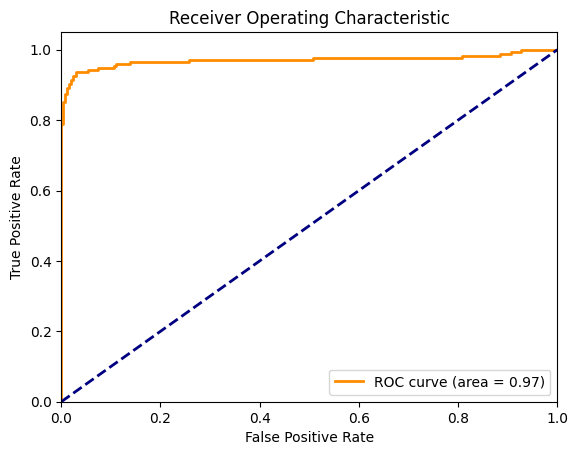

In [277]:
plot_roc_curve(labels_list, scores)

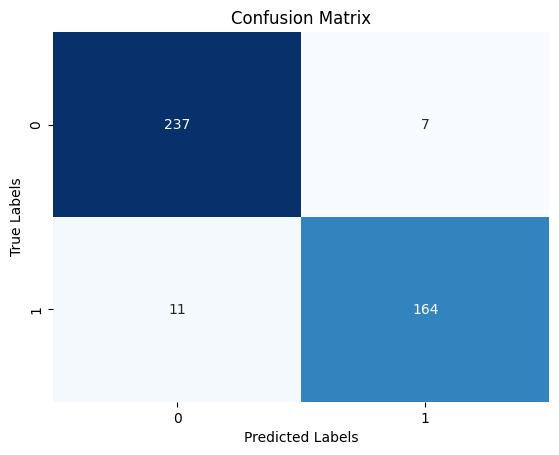

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       244
           1       0.96      0.94      0.95       175

    accuracy                           0.96       419
   macro avg       0.96      0.95      0.96       419
weighted avg       0.96      0.96      0.96       419

Confusion Matrix:
[[237   7]
 [ 11 164]]
Accuracy: 0.9570405727923628
Precision: 0.9590643274853801
Recall: 0.9371428571428572
DCS: 0.9479768786127168
AUC: 0.9710304449648711


In [278]:
calculate_metrics_and_confusion_matrix(labels_list, scores, 0.5)

# Part 2:
# CNN Model: Test Model 1

In [279]:
class CNN_Model_Test1(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
        nn.Conv2d(1,32, kernel_size=3 , padding=1),     # we want to extract 32 feature from this
        nn.BatchNorm2d(32),
        nn.ReLU(),                                      # Input: (batch_size, 1, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.2),
        nn.MaxPool2d(kernel_size=2, stride=2),          # Output: (batch_size, 32, 32, 32)
        nn.Conv2d(32, 32, kernel_size=3 , padding=1),   # Output: (batch_size, 32, 32, 32)
        nn.BatchNorm2d(32),
        nn.ReLU(),
        #nn.Dropout(0.2),
        nn.MaxPool2d(kernel_size=2, stride=2)    # Output: (batch_size, 32, 16, 16)
    )

    self.flat = nn.Flatten()   # Input: (batch_size, 32, 16, 16), Output: (batch_size, 32*16*16)

    self.classifier = nn.Sequential(
        nn.Linear(32*16*16, 128),  # Input: (batch_size, 8192), Output: (batch_size, 128)
        nn.ReLU(),
        nn.Linear(128, 2),           # Input: (batch_size, 128), Output: (batch_size, 2)
        nn.Softmax(dim=1)
    )
    """

    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           layer.weight.data.zero_()
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
           layer.weight.data.zero_()
           layer.bias.data.zero_()
    """
    # Xavier initialization for weights
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           torch.nn.init.xavier_uniform_(layer.weight,1)
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
            torch.nn.init.xavier_uniform_(layer.weight,1)
            layer.bias.data.zero_()


  def forward(self, x):
    x = self.feature_extractor(x)
    x = self.flat(x)
    x = self.classifier(x)
    return x

In [280]:
model_test1_1 = CNN_Model_Test1()
sample_model_test1_1, label_model_test1_1= next(iter(val_loader))
sample_model_test1_1

print(type(sample_model_test1_1))
print(sample_model_test1_1.shape)

sample_model_test1_1.float().shape

<class 'torch.Tensor'>
torch.Size([128, 1, 64, 64])


torch.Size([128, 1, 64, 64])

# Training model2: Test Model 1

In [281]:
#batch_size_model2 = 128
epochs = 30
learning_rate = 0.0001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_test1_2 = CNN_Model_Test1().to(device)

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimzier
optimizer_model_test1 = optim.Adam(model_test1_2.parameters(), lr=learning_rate)


acc_train_model_test1 = []
acc_val_model_test1 = []
loss_avg_train_model_test1 = []
loss_avg_val_model_test1 = []


for epoch in range(1, epochs + 1):
    sum_train_acc_epoch = 0
    sum_val_acc_epoch = 0
    sum_train_loss_epoch = 0
    sum_val_loss_epoch = 0

    model_test1_2.train()
    mode = "train"

    for batch_idx, (images, labels) in enumerate(train_loader,1):
        images = images.to(device)

        unique_classes = list(set(labels))
        labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
        labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)
        optimizer_model_test1.zero_grad()    # prevent accumulate the gradients

        labels = labels_tensor.to(device)
        labels_pred = model_test1_2(images.float())
        loss = loss_fn(labels_pred, labels.squeeze())


        #optimizer.zero_grad()    # prevent accumulate the gradients
        loss.backward()
        optimizer_model_test1.step()   # update the weights

        acc1 = accuracy_fn(labels_pred, labels.squeeze())
        sum_train_acc_epoch += acc1
        sum_train_loss_epoch += loss.detach().item()    # make independent from graph
        if batch_idx % int(round(len(train_loader)/6)) ==0:   # set how many times show the acc in each epoch
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for train ------>  {(sum_train_acc_epoch/batch_idx)*100}")
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for train ---------->  {sum_train_loss_epoch/batch_idx}")
    acc_train_model_test1.append(sum_train_acc_epoch / batch_idx)
    loss_avg_train_model_test1.append(sum_train_loss_epoch / batch_idx)

    model_test1_2.eval()
    mode = "val"

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader,1):
            images = images.to(device)

            unique_classes = list(set(labels))
            labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)

            labels = labels_tensor.to(device)
            labels_pred = model_test1_2(images.float())
            loss = loss_fn(labels_pred, labels.squeeze())
            acc1 = accuracy_fn(labels_pred, labels.squeeze())
            sum_val_acc_epoch += acc1
            sum_val_loss_epoch += loss.detach().item()
            if batch_idx % int(round(len(val_loader)/6)) ==0:
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for valid ------>  {(sum_val_acc_epoch/batch_idx)*100}")
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for valid ---------->  {sum_val_loss_epoch/batch_idx}")

        acc_val_model_test1.append(sum_val_acc_epoch / batch_idx)
        loss_avg_val_model_test1.append(sum_val_loss_epoch / len(val_loader))


At epoch 1, till batch_index 9: average accuracy for train ------>  57.03125
At epoch 1, till batch_index 9: average loss for train ---------->  0.7128331992361281
At epoch 1, till batch_index 18: average accuracy for train ------>  59.895833333333336
At epoch 1, till batch_index 18: average loss for train ---------->  0.6858158939414554
At epoch 1, till batch_index 27: average accuracy for train ------>  61.86342592592593
At epoch 1, till batch_index 27: average loss for train ---------->  0.6649234758483039
At epoch 1, till batch_index 36: average accuracy for train ------>  63.4765625
At epoch 1, till batch_index 36: average loss for train ---------->  0.6489065173599455
At epoch 1, till batch_index 45: average accuracy for train ------>  64.54861111111111
At epoch 1, till batch_index 45: average loss for train ---------->  0.6391395462883843
At epoch 1, till batch_index 54: average accuracy for train ------>  65.91435185185185
At epoch 1, till batch_index 54: average loss for train

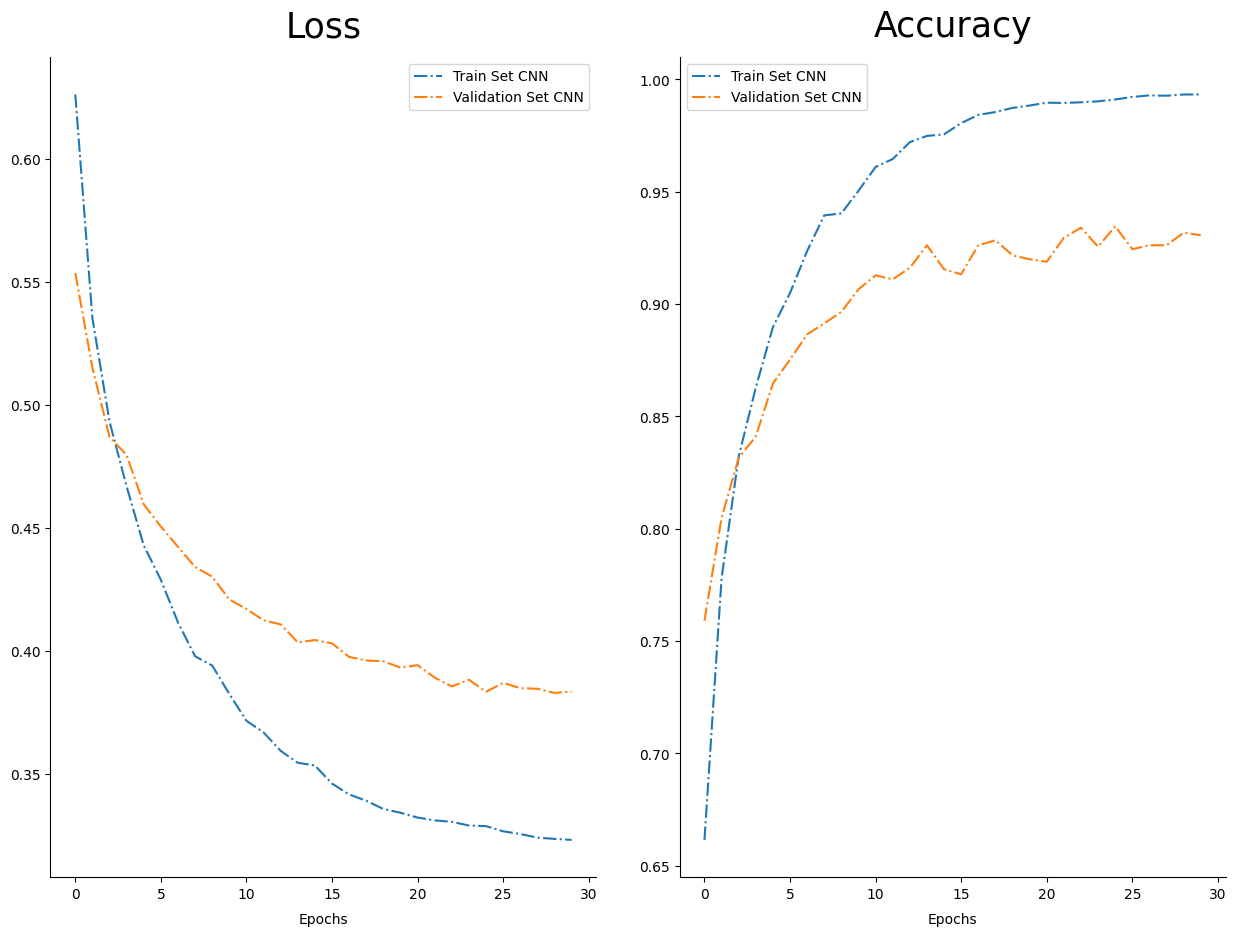

In [282]:
#plot the accuracy and loss curve
accloss_plots(loss_avg_train_model_test1, loss_avg_val_model_test1, acc_train_model_test1, acc_val_model_test1)

In [283]:
def eval_test(test_loader, model):    #&&&&&&&&&&&&&&&&&&&&&

    scores = []
    labels_list = []
    total_loss = 0
    total_samples = 0
    model.to(device)
    model.eval()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels_encoded = LabelEncoder().fit_transform(labels)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)
            labels = labels_tensor.to(device)
            labels_pred = model(images.float())

            loss = loss_fn(labels_pred.squeeze(), labels.squeeze())
            scores.extend(labels_pred.cpu().numpy()[:, 1])  # Use only the positive class scores
            labels_list.extend(labels.squeeze().cpu().numpy())
            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

    accuracy = accuracy_fn(labels_pred, labels.squeeze())
    loss = total_loss / total_samples

    return accuracy, loss, scores, labels_list

In [284]:
# Test Model Test1             #&&&&&&&&&&&&&&&&&&&&&
test_acc_mode_tets1, test_loss_mode_tets1, scores_mode_tets1, labels_list_mode_tets1 = eval_test(test_loader, model_test1_2)
print(f"Test accuracy for model test1: {test_acc_mode_tets1 * 100}%")
print(f"Test loss for model test1: {test_loss_mode_tets1}")
len(labels_list_mode_tets1)

Test accuracy for model test1: 91.42857193946838%
Test loss for model test1: 0.38493211073067424


419

# Plot the ROC for Model test 1

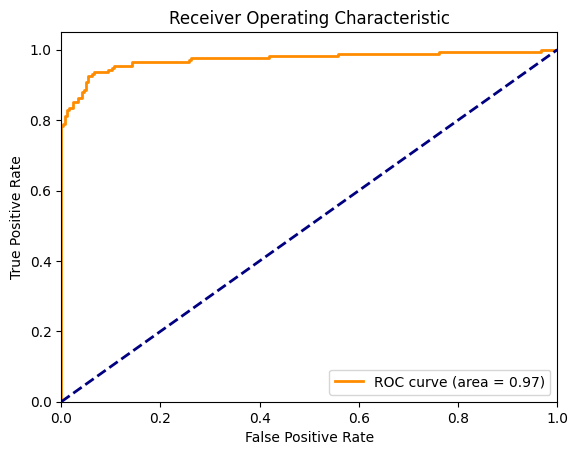

In [285]:
plot_roc_curve(labels_list_mode_tets1, scores_mode_tets1)

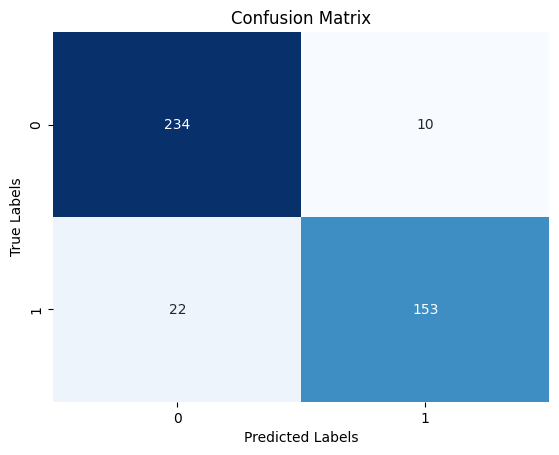

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.94       244
           1       0.94      0.87      0.91       175

    accuracy                           0.92       419
   macro avg       0.93      0.92      0.92       419
weighted avg       0.92      0.92      0.92       419

Confusion Matrix:
[[234  10]
 [ 22 153]]
Accuracy: 0.9236276849642004
Precision: 0.9386503067484663
Recall: 0.8742857142857143
DCS: 0.9053254437869822
AUC: 0.9731615925058548


In [286]:
calculate_metrics_and_confusion_matrix(labels_list_mode_tets1, scores_mode_tets1, 0.5)

# Part3
# CNN Model: Test Model 2

In [297]:
class CNN_Model_Test2(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
        nn.Conv2d(1,32, kernel_size=3 , padding=1),     # we want to extract 32 feature from this
        nn.BatchNorm2d(32),
        nn.ReLU(),                                      # Input: (batch_size, 1, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.5),
        nn.Conv2d(32,32, kernel_size=3 , padding=1),     # we want to extract 32 feature from this
        nn.BatchNorm2d(32),
        nn.ReLU(),                                      # Input: (batch_size, 32, 64, 64), Output: (batch_size, 32, 64, 64)
        #nn.Dropout(0.5),
        nn.MaxPool2d(kernel_size=2, stride=2),          # Output: (batch_size, 32, 32, 32)
    )

    self.flat = nn.Flatten()   # Input: (batch_size, 32, 16, 16), Output: (batch_size, 32*16*16)

    self.classifier = nn.Sequential(
        nn.Linear(32*32*32, 128),  # Input: (batch_size, 32*32*32), Output: (batch_size, 128)
        nn.ReLU(),
        nn.Linear(128, 64),  # Input: (batch_size, 128), Output: (batch_size, 64)
        nn.ReLU(),
        nn.Linear(64, 2),           # Input: (batch_size, 64), Output: (batch_size, 2)
        nn.Softmax(dim=1)
    )
    """
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           layer.weight.data.zero_()
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
           layer.weight.data.zero_()
           layer.bias.data.zero_()
    """
    # Xavier initialization for weights
    for layer in self.feature_extractor:
        if isinstance(layer, nn.Conv2d):
           torch.nn.init.xavier_uniform_(layer.weight,1)
           layer.bias.data.zero_()

    for layer in self.classifier:
        if isinstance(layer, nn.Linear):
            torch.nn.init.xavier_uniform_(layer.weight,1)
            layer.bias.data.zero_()

  def forward(self, x):
    x = self.feature_extractor(x)
    x = self.flat(x)
    x = self.classifier(x)
    return x

In [298]:
model_test2_1 = CNN_Model_Test2()
sample_model_test2_1, label_model_test2_1= next(iter(val_loader))
sample_model_test2_1

print(type(sample_model_test2_1))
print(sample_model_test2_1.shape)

model_test2_1(sample_model_test2_1.float()).shape

<class 'torch.Tensor'>
torch.Size([128, 1, 64, 64])


torch.Size([128, 2])

# Training model3: Test Model 2

In [299]:
#batch_size_model3 = 128
epochs_2 = 30
learning_rate_2 = 0.0001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_test2_2 = CNN_Model_Test2().to(device)

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimzier
optimizer_model_test2 = optim.Adam(model_test2_2.parameters(), lr=learning_rate_2)


acc_train_model_test2 = []
acc_val_model_test2 = []
loss_avg_train_model_test2 = []
loss_avg_val_model_test2 = []


for epoch in range(1, epochs_2 + 1):
    sum_train_acc_epoch = 0
    sum_val_acc_epoch = 0
    sum_train_loss_epoch = 0
    sum_val_loss_epoch = 0

    model_test2_2.train()
    mode = "train"

    for batch_idx, (images, labels) in enumerate(train_loader,1):
        images = images.to(device)

        unique_classes = list(set(labels))
        labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
        labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)
        optimizer_model_test2.zero_grad()    # prevent accumulate the gradients

        labels = labels_tensor.to(device)
        labels_pred = model_test2_2(images.float())
        loss = loss_fn(labels_pred, labels.squeeze())


        #optimizer.zero_grad()    # prevent accumulate the gradients
        loss.backward()
        optimizer_model_test2.step()   # update the weights

        #acc1 = accuracy(labels_pred, labels.squeeze())
        acc1 = accuracy_fn(labels_pred, labels.squeeze())
        sum_train_acc_epoch += acc1
        #sum_train_acc_epoch += acc1[0]
        sum_train_loss_epoch += loss.detach().item()    # make independent from graph
        if batch_idx % int(round(len(train_loader)/6)) ==0:   # set how many times show the acc in each epoch
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for train ------>  {(sum_train_acc_epoch/batch_idx)*100}")
            print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for train ---------->  {sum_train_loss_epoch/batch_idx}")
    acc_train_model_test2.append(sum_train_acc_epoch / batch_idx)
    loss_avg_train_model_test2.append(sum_train_loss_epoch / batch_idx)

    model_test2_2.eval()
    mode = "val"

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader,1):
            images = images.to(device)

            unique_classes = list(set(labels))
            labels_encoded = LabelEncoder().fit_transform(labels)  #labels_encoded is a numpy.ndarray with the shape of (256,)
            labels_tensor = torch.from_numpy(labels_encoded).unsqueeze(1)

            labels = labels_tensor.to(device)
            labels_pred = model_test2_2(images.float())
            loss = loss_fn(labels_pred, labels.squeeze())
            acc1 = accuracy_fn(labels_pred, labels.squeeze())
            sum_val_acc_epoch += acc1
            sum_val_loss_epoch += loss.detach().item()
            if batch_idx % int(round(len(val_loader)/6)) ==0:
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average accuracy for valid ------>  {(sum_val_acc_epoch/batch_idx)*100}")
                print(f"At epoch {epoch}, till batch_index {batch_idx}: average loss for valid ---------->  {sum_val_loss_epoch/batch_idx}")

        acc_val_model_test2.append(sum_val_acc_epoch / batch_idx)
        loss_avg_val_model_test2.append(sum_val_loss_epoch / len(val_loader))


At epoch 1, till batch_index 9: average accuracy for train ------>  56.68402777777778
At epoch 1, till batch_index 9: average loss for train ---------->  0.7221417956882052
At epoch 1, till batch_index 18: average accuracy for train ------>  56.510416666666664
At epoch 1, till batch_index 18: average loss for train ---------->  0.7121300730440352
At epoch 1, till batch_index 27: average accuracy for train ------>  59.201388888888886
At epoch 1, till batch_index 27: average loss for train ---------->  0.6857972939809164
At epoch 1, till batch_index 36: average accuracy for train ------>  61.9140625
At epoch 1, till batch_index 36: average loss for train ---------->  0.6643242885669073
At epoch 1, till batch_index 45: average accuracy for train ------>  63.68055555555555
At epoch 1, till batch_index 45: average loss for train ---------->  0.6507955869038899
At epoch 1, till batch_index 54: average accuracy for train ------>  65.49479166666666
At epoch 1, till batch_index 54: average loss

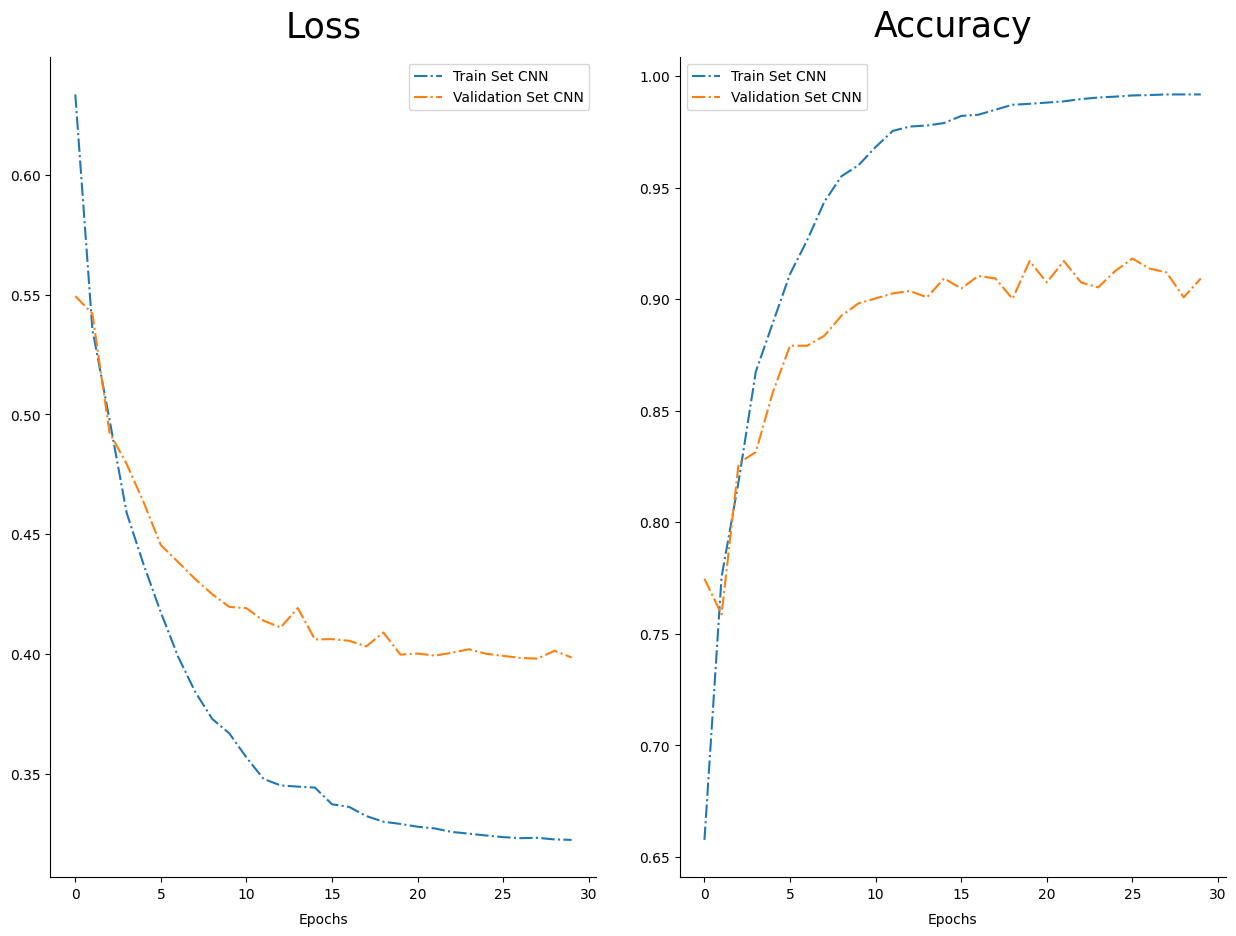

In [300]:
#plot the accuracy and loss curve
accloss_plots(loss_avg_train_model_test2, loss_avg_val_model_test2, acc_train_model_test2, acc_val_model_test2)

In [301]:
# Test Proposed Model                 #&&&&&&&&&&&&&&&&&&&&&
test_acc_mode_tets2, test_loss_mode_tets2, scores_mode_tets2, labels_list_mode_tets2 = eval_test(test_loader, model_test2_2)
print(f"Test accuracy for model test2: {test_acc_mode_tets2 * 100}%")
print(f"Test loss forfor model test2: {test_loss_mode_tets2}")
len(labels_list_mode_tets2)

Test accuracy for model test2: 91.42857193946838%
Test loss forfor model test2: 0.38219304578401025


419

# Plot the ROC for Model test 2

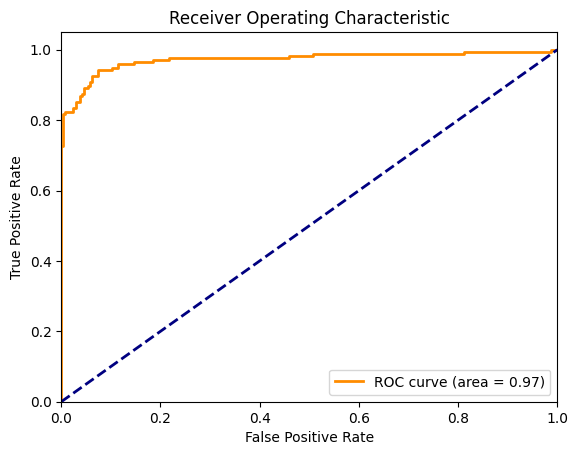

In [302]:
plot_roc_curve(labels_list_mode_tets2, scores_mode_tets2)

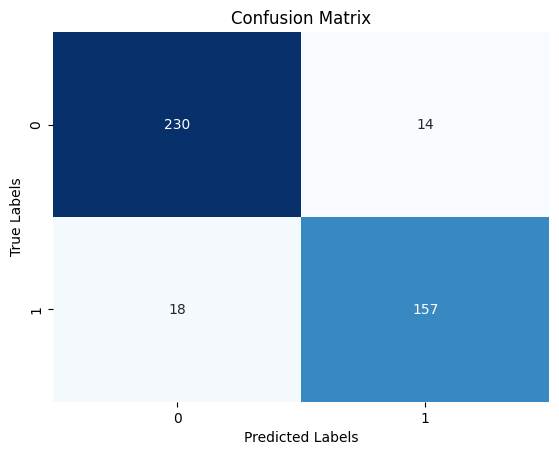

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93       244
           1       0.92      0.90      0.91       175

    accuracy                           0.92       419
   macro avg       0.92      0.92      0.92       419
weighted avg       0.92      0.92      0.92       419

Confusion Matrix:
[[230  14]
 [ 18 157]]
Accuracy: 0.9236276849642004
Precision: 0.9181286549707602
Recall: 0.8971428571428571
DCS: 0.9075144508670521
AUC: 0.9730444964871193


In [303]:
calculate_metrics_and_confusion_matrix(labels_list_mode_tets2, scores_mode_tets2, 0.5)